# Notebook 01: dataset y entrenamiento de YOLO26

Entrenamos un detector YOLO26 para dos clases que no están en COCO: `mate` (ID 0) y `termo` (ID 1). Partimos de pesos preentrenados en COCO (transfer learning).

El notebook valida las etiquetas, arma una partición train/val/test por sesiones de fotos, compara cuatro configuraciones de entrenamiento y evalúa la elegida en test. El modelo y el umbral de confianza se eligen con validación; test se usa una sola vez, al final.

La primera corrida, con otras etiquetas y otro split, quedó en `resultados/historico_original/`. Las correcciones al dataset están en `docs/dataset_y_entrenamiento.md`.

## 1. Preparación en Google Colab

1. Abrir el notebook en Colab y elegir **Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4)**.
2. Ejecutar todas las celdas con **Entorno de ejecución > Ejecutar todas**.

La celda siguiente clona el repositorio en `/content/CV-mate-detection`, con las fotos, las etiquetas y el split. Si en `/content` hay un `CV_mate_termo_Colab.zip` con el proyecto, lo descomprime en lugar de clonar. Fuera de Colab no hace nada y el notebook usa el repositorio local.

El entrenamiento necesita GPU: sin CUDA, la celda de la sección 7 se detiene. Los archivos de `/content` se borran al cerrar la sesión, así que al terminar hay que descargar `entregable_entrenamiento.zip`.

In [1]:
import os
import subprocess
import zipfile
from pathlib import Path

REPO_URL = 'https://github.com/bpace1/CV-mate-detection.git'
colab_root = Path('/content/CV-mate-detection')
if Path('/content').exists():
    package_path = Path('/content/CV_mate_termo_Colab.zip')
    if (colab_root / 'data/source_groups.csv').exists():
        pass
    elif package_path.exists():
        content_root = Path('/content').resolve()
        with zipfile.ZipFile(package_path) as archive:
            for member in archive.namelist():
                target = (content_root / member).resolve()
                if not target.is_relative_to(content_root):
                    raise ValueError('El ZIP contiene una ruta no permitida.')
            archive.extractall(content_root)
    else:
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL,
                        str(colab_root)], check=True)
    os.chdir(colab_root / 'notebooks')
    print('Proyecto listo:', colab_root)


Web: seleccionar el ZIP. VS Code: usar Upload to Colab.


Saving CV_mate_termo_Colab.zip to CV_mate_termo_Colab.zip
Proyecto listo: /content/CV-mate-detection


In [2]:
# Mantener torch/CUDA del entorno (en Colab ya está instalado).
from pathlib import Path

requirements_file = Path('requirements-training.txt')
if not requirements_file.exists():
    requirements_file = Path('../requirements-training.txt')
%pip -q install -r {requirements_file}


In [3]:
import contextlib
import hashlib
import json
import os
import random
import shutil
import sys
import zipfile
from datetime import datetime
from pathlib import Path

import cv2
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image as IPyImage
from IPython.display import display
from PIL import Image, ImageOps
from ultralytics import YOLO

IN_COLAB = 'google.colab' in sys.modules or os.path.exists('/content')


def resolve_root() -> Path:
    """Devuelve la raíz del proyecto según el entorno de ejecución.

    En Colab prefiere el proyecto cargado en ``/content``. Si no existe,
    intenta usar ``MyDrive/Proyecto_Integrador_YOLO26``. En local usa el
    directorio padre cuando el notebook corre desde ``notebooks/``.

    Returns:
        Directorio raíz del repositorio.
    """
    if not IN_COLAB:
        cwd = Path.cwd()
        return cwd.parent if cwd.name == 'notebooks' else cwd
    colab_repo = Path('/content/CV-mate-detection')
    if colab_repo.exists():
        return colab_repo
    try:
        from google.colab import drive

        drive.mount('/content/drive')
    except Exception as exc:  # noqa: BLE001 - Drive es opcional.
        print('Advertencia al montar Drive:', exc)
        return colab_repo if colab_repo.exists() else Path.cwd()
    drive_root = Path('/content/drive/MyDrive/Proyecto_Integrador_YOLO26')
    return drive_root if drive_root.exists() else colab_repo


ROOT = resolve_root()
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RAW = ROOT / 'dataset'
LABELS = ROOT / 'data' / 'unified' / 'labels'
SOURCE_VIDEOS = ROOT / 'videos' / 'fuente_dataset'
DATASET = ROOT / 'dataset_yolo26_mate_termo'
RUNS = ROOT / 'entrenamientos'
for folder in (RAW, LABELS, SOURCE_VIDEOS, RUNS):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = {0: 'mate', 1: 'termo'}
IMAGE_SUFFIXES = {'.jpg', '.jpeg', '.png', '.webp'}

print('=== ENTORNO DE EJECUCIÓN ===')
print('Modo Colab:', IN_COLAB)
print('Directorio raíz (ROOT):', ROOT)
print('Directorio de imágenes (RAW):', RAW)
print('Directorio de etiquetas (LABELS):', LABELS)
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'No disponible (CPU)')
print('Ultralytics:', __import__('ultralytics').__version__)

# Permite importar helpers al ejecutar desde notebooks/ o desde la raíz.
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.training_utils import (
    assign_groups,
    calibrate_confidence,
    collect_predictions,
    operational_metrics,
    persistent_split,
    save_predictions,
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
=== ENTORNO DE EJECUCIÓN ===
Modo Colab: True
Directorio raíz (ROOT): /content/CV-mate-detection
Directorio de imágenes (RAW): /content/CV-mate-detection/dataset
Directorio de etiquetas (LABELS): /content/CV-mate-detection/data/unified/labels
GPU: Tesla T4
Ultralytics: 8.4.202


## 2. Recolección de imágenes

El enunciado pide al menos 50 imágenes por clase. Importa más la variedad que la cantidad: 100 fotogramas casi iguales de un mismo video no valen lo mismo que 100 fotos distintas.

1. Guardar las fotos originales en `dataset/`, solo de uso permitido.
2. Registrar la URL, el autor, la licencia y la fecha de cada foto que no sea propia.
3. Para extraer fotogramas de un video, ponerlo en `videos/fuente_dataset/`.
4. Nombrar los fotogramas de un mismo video como `fuente01__f00000120.jpg`. El split usa el prefijo antes de `__` para que los cuadros de un video no queden repartidos entre train y test.

Conviene variar el mate, la bombilla, el termo, el fondo, la distancia, la luz y la oclusión, y sumar fotos con los dos objetos juntos. También sirven algunas fotos sin mate ni termo, con un `.txt` vacío.

### 2.1. Opcional: extraer fotogramas de videos

La celda guarda un fotograma cada 2 segundos de cada video de `videos/fuente_dataset/`. Esos fotogramas después hay que anotarlos a mano. No poner dos copias del mismo video como si fueran fuentes distintas.

In [4]:
EXTRAER_FOTOGRAMAS = False  # True cuando haya videos en SOURCE_VIDEOS
INTERVALO_SEGUNDOS = 2.0


def extract_frames(video: Path, out_dir: Path, interval_s: float) -> int:
    """Guarda un fotograma cada ``interval_s`` segundos de un video.

    Los archivos se nombran ``<video>__f<nro>.jpg``: el prefijo antes de
    ``__`` agrupa los cuadros de un mismo video en el split.

    Args:
        video: Video de origen.
        out_dir: Carpeta donde guardar los fotogramas.
        interval_s: Segundos entre fotogramas guardados.

    Returns:
        Cantidad de fotogramas nuevos escritos.
    """
    cap = cv2.VideoCapture(str(video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        cap.release()
        print('Se omite (FPS inválido):', video.name)
        return 0
    step = max(1, round(fps * interval_s))
    frame_id = 0
    generated = 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        target = out_dir / f'{video.stem}__f{frame_id:08d}.jpg'
        if frame_id % step == 0 and not target.exists():
            cv2.imwrite(str(target), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
            generated += 1
        frame_id += 1
    cap.release()
    return generated


if EXTRAER_FOTOGRAMAS:
    for video in sorted(SOURCE_VIDEOS.glob('*.mp4')):
        nuevos = extract_frames(video, RAW, INTERVALO_SEGUNDOS)
        print(video.name, 'nuevos fotogramas:', nuevos)
n_raw = sum(p.suffix.lower() in IMAGE_SUFFIXES for p in RAW.iterdir())
print('Imágenes sin particionar:', n_raw)


Imágenes sin particionar: 90


## 3. Anotación

En [MakeSense](https://www.makesense.ai/) o una herramienta parecida:

1. Cargar las imágenes de `dataset/`.
2. Crear las etiquetas en este orden: `mate` (ID 0) y `termo` (ID 1).
3. Dibujar cajas ajustadas al borde visible de cada objeto. Marcar todos los mates y termos de la foto, y nada más.
4. Exportar en formato YOLO (un `.txt` por imagen) o como CSV. Los CSV van a `data/raw_annotations/` y se convierten con `src/unify_annotations.py`; los `.txt` terminan en `data/unified/labels/`.
5. Si el export trae un `classes.txt`, revisar que diga `mate` y `termo` en ese orden.
6. Cada imagen con un objeto necesita su `.txt`. Una imagen sin mate ni termo lleva un `.txt` vacío.

Para pasar las fotos de Drive al anotador, la celda siguiente puede comprimirlas en un ZIP.

In [5]:
# Opcional: ZIP de fotografías para importar en la herramienta de anotación.
CREAR_ZIP_PARA_ETIQUETAR = False
if CREAR_ZIP_PARA_ETIQUETAR:
    destino = ROOT / 'imagenes_para_etiquetar.zip'
    with zipfile.ZipFile(destino, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
        for file in sorted(RAW.iterdir()):
            if file.suffix.lower() in IMAGE_SUFFIXES:
                zf.write(file, file.name)
    print('ZIP creado:', destino)


## 4. Validación de etiquetas

La celda corta la ejecución si encuentra una imagen ilegible o duplicada (mismo contenido de píxeles), una etiqueta con formato inválido, una clase desconocida, una caja fuera de la imagen, un `classes.txt` en otro orden o menos de 10 fuentes distintas. Si alguna clase tiene menos de 50 imágenes, solo avisa.

El mínimo de 50 cuenta imágenes que contienen la clase, no cajas.

In [6]:
MIN_IMAGENES_POR_CLASE = 50
MIN_GRUPOS = 10


class DatasetError(ValueError):
    """El dataset no cumple los requisitos para entrenar."""


def read_yolo_label(label_path: Path) -> list[int]:
    """Lee y valida un archivo de etiquetas YOLO.

    Args:
        label_path: Archivo ``.txt`` con una caja por línea.

    Returns:
        IDs de clase de cada caja (vacía si es una imagen negativa).

    Raises:
        ValueError: Si alguna línea no tiene 5 columnas, la clase no existe o
            la caja sale del área normalizada.
    """
    eps = 1e-4
    class_ids = []
    text = label_path.read_text(encoding='utf-8-sig')
    for lineno, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            raise ValueError(f'línea {lineno}: se requieren 5 columnas')
        cls_raw = float(parts[0])
        cls = int(cls_raw)
        if cls_raw != cls or cls not in CLASSES:
            raise ValueError(f'línea {lineno}: clase inválida {parts[0]}')
        x, y, w, h = map(float, parts[1:])
        if not np.all(np.isfinite([x, y, w, h])):
            raise ValueError(f'línea {lineno}: valores no finitos')
        if not (0 < w <= 1 + eps and 0 < h <= 1 + eps):
            raise ValueError(f'línea {lineno}: ancho/alto inválido')
        inside = (-eps <= x - w / 2 and x + w / 2 <= 1 + eps
                  and -eps <= y - h / 2 and y + h / 2 <= 1 + eps)
        if not inside:
            raise ValueError(f'línea {lineno}: caja fuera de la imagen')
        class_ids.append(cls)
    return class_ids


def image_digest(image_path: Path) -> str:
    """Calcula un hash de los píxeles decodificados de una imagen.

    Detecta duplicados aunque los archivos difieran en metadatos o
    compresión.

    Args:
        image_path: Imagen a procesar.

    Returns:
        SHA-256 de los píxeles RGB y del tamaño.

    Raises:
        ValueError: Si la imagen mide menos de 64 px de lado.
        OSError: Si la imagen está corrupta.
    """
    with Image.open(image_path) as img:
        img.verify()
    with Image.open(image_path) as img:
        if img.width < 64 or img.height < 64:
            raise ValueError('dimensiones muy pequeñas')
        payload = img.convert('RGB').tobytes() + f'{img.size}'.encode()
    return hashlib.sha256(payload).hexdigest()


def build_records(
    images: list[Path], labels_dir: Path,
) -> tuple[list[dict], list[str], list[str]]:
    """Empareja imágenes con etiquetas y valida ambas.

    El grupo de cada imagen es el prefijo antes de ``__`` (fotogramas de un
    mismo video) o el nombre completo si no lo tiene.

    Args:
        images: Imágenes candidatas.
        labels_dir: Carpeta con los ``.txt`` YOLO.

    Returns:
        ``(records, unlabeled, errors)``. Cada record tiene ``image``,
        ``label``, ``group``, ``class_ids`` y ``boxes``.
    """
    records = []
    unlabeled = []
    errors = []
    seen_hashes = {}
    for image in images:
        label = labels_dir / f'{image.stem}.txt'
        if not label.is_file():
            unlabeled.append(image.name)
            continue
        try:
            digest = image_digest(image)
        except Exception as exc:  # noqa: BLE001 - se reporta cualquier fallo.
            errors.append(f'Imagen ilegible: {image.name}: {exc}')
            continue
        if digest in seen_hashes:
            errors.append(f'Imagen duplicada: {image.name} y '
                          f'{seen_hashes[digest]}')
            continue
        seen_hashes[digest] = image.name
        try:
            class_ids = read_yolo_label(label)
        except ValueError as exc:
            errors.append(f'{label.name}: {exc}')
            continue
        group = image.stem.split('__', 1)[0]
        records.append({'image': image, 'label': label, 'group': group,
                        'class_ids': set(class_ids), 'boxes': len(class_ids)})
    return records, unlabeled, errors


images = sorted(p for p in RAW.iterdir()
                if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)
if not images:
    raise DatasetError(f'Faltan imágenes. Colocarlas en {RAW} (sección 2).')
stems = [p.stem for p in images]
if len(stems) != len(set(stems)):
    raise DatasetError('Hay imágenes con el mismo nombre y distinta '
                       'extensión; renombrarlas.')

classes_file = LABELS / 'classes.txt'
if classes_file.exists():
    declared = [s.strip().lower() for s in
                classes_file.read_text(encoding='utf-8-sig').splitlines()
                if s.strip()]
    if declared != list(CLASSES.values()):
        raise DatasetError(f'Orden de clases incorrecto: {declared}. '
                           'Se requiere mate, termo.')

records, unlabeled_images, errors = build_records(images, LABELS)
if unlabeled_images:
    print(f'[AVISO] {len(unlabeled_images)} imágenes sin .txt (se omiten):',
          unlabeled_images)
if errors:
    print('\n'.join(errors[:30]))
    raise DatasetError(f'Corregir los {len(errors)} problemas antes de '
                       'continuar.')

counts = {name: sum(idx in rec['class_ids'] for rec in records)
          for idx, name in CLASSES.items()}
assign_groups(records, ROOT / 'data/source_groups.csv')
n_groups = len({rec['group'] for rec in records})
print('=== RESUMEN DEL DATASET VALIDADO ===')
print('Imágenes con cada clase:', counts)
print('Imágenes únicas procesables:', len(records), '| grupos/fuentes:',
      n_groups)

faltantes = {name: MIN_IMAGENES_POR_CLASE - n for name, n in counts.items()
             if n < MIN_IMAGENES_POR_CLASE}
if faltantes:
    print('[ADVERTENCIA] El enunciado exige al menos '
          f'{MIN_IMAGENES_POR_CLASE} imágenes por clase. Faltan: {faltantes}')
if n_groups < MIN_GRUPOS:
    raise DatasetError(f'Hay menos de {MIN_GRUPOS} fuentes independientes. '
                       'Reunir más diversidad.')


=== RESUMEN DEL DATASET VALIDADO ===
Imágenes con cada clase: {'mate': 62, 'termo': 50}
Imágenes únicas procesables: 90 | grupos/fuentes: 40


## 5. Inspección visual

Que la validación pase no garantiza que las cajas estén bien puestas. La celda muestra 8 imágenes al azar con sus cajas para revisarlas a ojo.

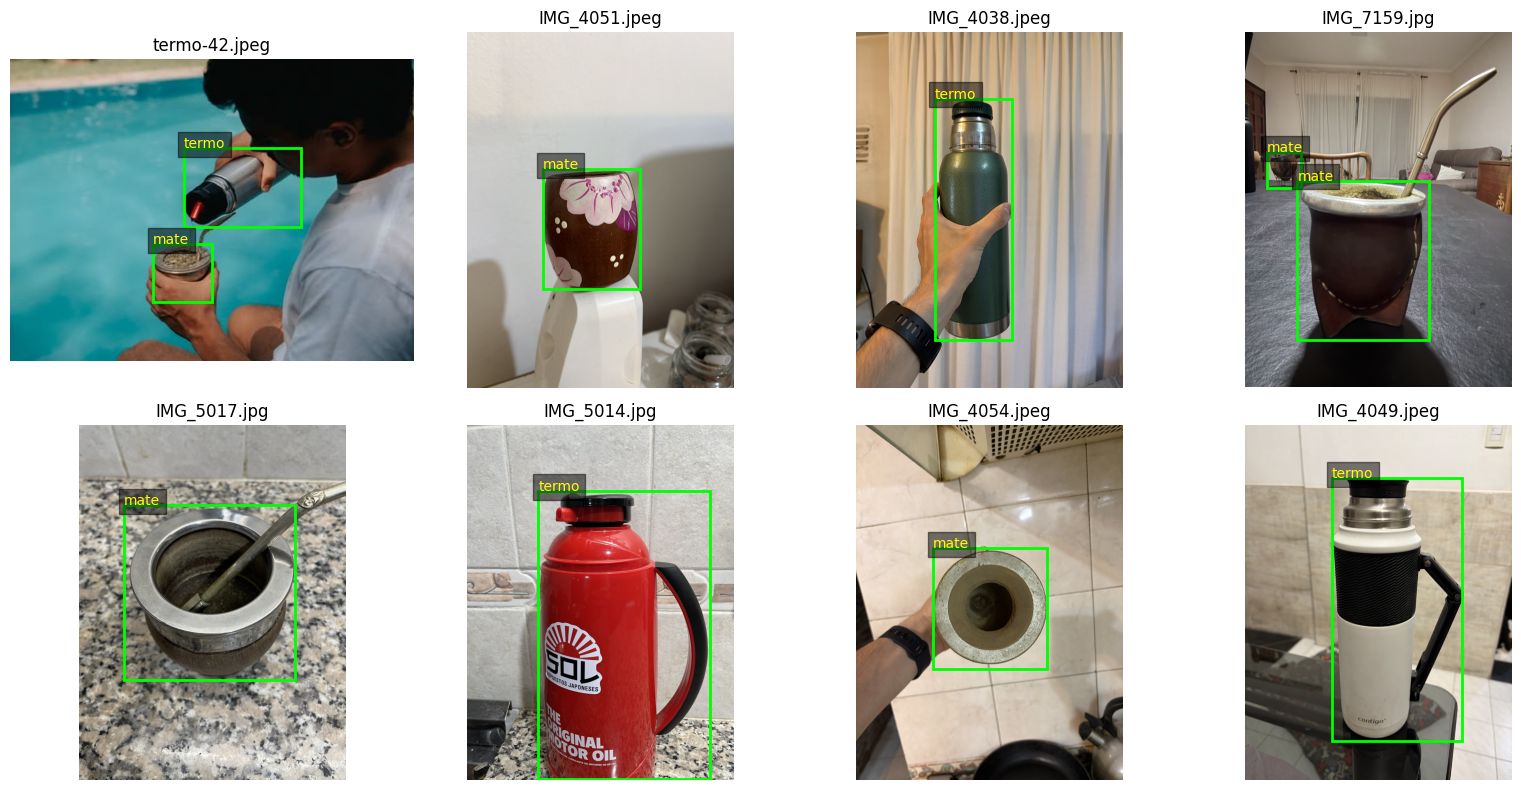

In [7]:
def plot_labeled_samples(records: list[dict], k: int = 8) -> None:
    """Muestra ``k`` imágenes al azar con sus cajas dibujadas.

    Args:
        records: Records devueltos por ``build_records``.
        k: Cantidad de imágenes a mostrar (máximo 8).
    """
    sample = random.sample(records, k=min(k, len(records), 8))
    fig, axs = plt.subplots(2, 4, figsize=(16, 8))
    axs = axs.ravel()
    for ax, rec in zip(axs, sample, strict=False):
        with Image.open(rec['image']) as img:
            im = ImageOps.exif_transpose(img).convert('RGB')
        ax.imshow(im)
        ww, hh = im.size
        for line in rec['label'].read_text().splitlines():
            if not line.strip():
                continue
            cls, xc, yc, bw, bh = map(float, line.split())
            x0 = (xc - bw / 2) * ww
            y0 = (yc - bh / 2) * hh
            ax.add_patch(patches.Rectangle((x0, y0), bw * ww, bh * hh,
                                           fill=False, edgecolor='lime',
                                           linewidth=2))
            ax.text(x0, max(2, y0), CLASSES[int(cls)], color='yellow',
                    bbox={'facecolor': 'black', 'alpha': 0.5})
        ax.set_title(rec['image'].name[:28])
        ax.axis('off')
    for ax in axs[len(sample):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


plot_labeled_samples(records)


## 6. Partición por sesiones

Las fotos de una misma sesión (mismo lugar, misma luz, mismos objetos) se parecen mucho. Si quedan repartidas entre train y test, el test mide memoria y no generalización. Por eso el split mantiene juntas las sesiones de `data/source_groups.csv` y apunta a 70/15/15 en cantidad de imágenes. Las sesiones las identificamos mirando las fotos; no salen de metadatos de la cámara.

La primera ejecución escribe `data/split_manifest.csv`, con el hash de cada imagen y de cada etiqueta. Las siguientes reutilizan ese split y se detienen si algún archivo cambió. El split no se rehace para mejorar el resultado en test.

In [8]:
def summarize_splits(splits: dict[str, list[dict]]) -> pd.DataFrame:
    """Cuenta imágenes, grupos e imágenes por clase de cada split.

    Args:
        splits: Registros por split.

    Returns:
        Una fila por split.
    """
    rows = []
    for split, subset in splits.items():
        row = {'split': split, 'total': len(subset),
               'grupos': len({rec['group'] for rec in subset})}
        row.update({name: sum(i in rec['class_ids'] for rec in subset)
                    for i, name in CLASSES.items()})
        rows.append(row)
    return pd.DataFrame(rows)


def write_yolo_dataset(splits: dict[str, list[dict]],
                       dataset_dir: Path) -> Path:
    """Copia imágenes y etiquetas a la estructura YOLO y escribe data.yaml.

    Borra ``dataset_dir`` antes de escribir.

    Args:
        splits: Registros por split.
        dataset_dir: Carpeta destino.

    Returns:
        Ruta del ``data.yaml`` generado.
    """
    expected = (ROOT / 'dataset_yolo26_mate_termo').resolve()
    if dataset_dir.resolve() != expected or dataset_dir.is_symlink():
        raise ValueError('Destino de dataset no permitido.')
    if dataset_dir.exists():
        shutil.rmtree(dataset_dir)
    for split, subset in splits.items():
        image_dir = dataset_dir / 'images' / split
        label_dir = dataset_dir / 'labels' / split
        image_dir.mkdir(parents=True)
        label_dir.mkdir(parents=True)
        for rec in subset:
            shutil.copy2(rec['image'], image_dir / rec['image'].name)
            shutil.copy2(rec['label'], label_dir / rec['label'].name)
    config = {'path': str(dataset_dir), 'train': 'images/train',
              'val': 'images/val', 'test': 'images/test', 'names': CLASSES}
    data_yaml = dataset_dir / 'data.yaml'
    data_yaml.write_text(yaml.safe_dump(config, sort_keys=False,
                                        allow_unicode=True), encoding='utf-8')
    return data_yaml


splits = persistent_split(
    records, ROOT / 'data/split_manifest.csv', SEED,
)
df_summary = summarize_splits(splits)
display(df_summary)
if (df_summary[list(CLASSES.values())] < 1).to_numpy().any():
    raise DatasetError('Una clase quedó ausente de train, val o test. '
                       'Hacen falta más fuentes o cambiar el split.')
DATA_YAML = write_yolo_dataset(splits, DATASET)
df_summary.to_csv(DATASET / 'recuento_split.csv', index=False)
print(DATA_YAML.read_text(encoding='utf-8'))

shutil.copy2(ROOT / 'data/split_manifest.csv', DATASET / 'split_manifest.csv')


,split,total,grupos,mate,termo
0,train,63,25,43,36
1,val,13,7,9,7
2,test,14,8,10,7


path: /content/CV-mate-detection/dataset_yolo26_mate_termo
train: images/train
val: images/val
test: images/test
names:
  0: mate
  1: termo



PosixPath('/content/CV-mate-detection/dataset_yolo26_mate_termo/split_manifest.csv')

## 7. Comparación de configuraciones

Entrenamos cuatro candidatos que solo difieren en el modelo base y en la probabilidad de mosaic:

| Candidato | Modelo base | Mosaic |
|---|---|---|
| `n_mosaic100` | `yolo26n.pt` | 1.0 |
| `n_sin_mosaic` | `yolo26n.pt` | 0.0 |
| `n_mosaic50` | `yolo26n.pt` | 0.5 |
| `s_mosaic50` | `yolo26s.pt` | 0.5 |

Comparten split, semilla 42, imágenes de 640 px, batch 16 y hasta 80 épocas, con early stopping a las 20 sin mejora. Mosaic se apaga en las últimas 60 épocas (`close_mosaic=60`), es decir, desde la época 21. El resto de los aumentos son los que Ultralytics 8.4.202 usa por defecto.

Gana el candidato con mayor mAP50-95 en validación. Con una sola semilla por candidato, una diferencia de un punto puede ser ruido.

In [9]:
EPOCHS = 80
IMGSZ = 640
BATCH = 16 if IN_COLAB else 4  # Mismo batch para todos los candidatos.
PATIENCE = 20
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
SUITE_NAME = 'comparacion_' + datetime.now().strftime('%Y%m%d_%H%M%S')
SUITE = RUNS / SUITE_NAME
SUITE.mkdir(parents=True, exist_ok=False)
EXPERIMENTS = [
    {'name': 'n_mosaic100', 'model': 'yolo26n.pt', 'mosaic': 1.0},
    {'name': 'n_sin_mosaic', 'model': 'yolo26n.pt', 'mosaic': 0.0},
    {'name': 'n_mosaic50', 'model': 'yolo26n.pt', 'mosaic': 0.5},
    {'name': 's_mosaic50', 'model': 'yolo26s.pt', 'mosaic': 0.5},
]
if DEVICE == 'cpu':
    raise RuntimeError('Se requiere CUDA para ejecutar esta comparación. '
                       'En Colab habilitar GPU antes de continuar.')

environment = {
    'python': sys.version, 'torch': torch.__version__,
    'ultralytics': __import__('ultralytics').__version__,
    'gpu': torch.cuda.get_device_name(0), 'seed': SEED,
    'split_sha256': hashlib.sha256(
        (ROOT / 'data/split_manifest.csv').read_bytes()).hexdigest(),
    'epochs': EPOCHS, 'batch': BATCH, 'imgsz': IMGSZ,
    'patience': PATIENCE, 'close_mosaic': 60,
    'workers': 2 if IN_COLAB else 0,
    'experiments': EXPERIMENTS,
}
(SUITE / 'configuracion.json').write_text(
    json.dumps(environment, indent=2), encoding='utf-8')
# Un renglón por época; el log completo se guarda aparte.
progress_stream = sys.stdout


def print_epoch_progress(trainer) -> None:
    """Muestra el avance sin volcar barras de progreso al notebook.

    Args:
        trainer: Entrenador de Ultralytics.
    """
    score = trainer.metrics.get('metrics/mAP50-95(B)', 0.0)
    print(f'{trainer.args.name}: época {trainer.epoch + 1}/{trainer.epochs}'
          f' | val mAP50-95={score:.3f}', file=progress_stream, flush=True)


comparison = []
for experiment in EXPERIMENTS:
    print('Entrenando:', experiment)
    detector = YOLO(experiment['model'])
    detector.add_callback('on_fit_epoch_end', print_epoch_progress)
    with (SUITE / (experiment['name'] + '.log')).open(
        'w', encoding='utf-8',
    ) as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
        detector.train(
            data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
            patience=PATIENCE, seed=SEED, device=DEVICE, project=str(SUITE),
            name=experiment['name'], exist_ok=False, save=True, plots=True,
            workers=environment['workers'], cache=False,
            mosaic=experiment['mosaic'],
            close_mosaic=60, optimizer='auto', deterministic=True,
        )
    run_dir = Path(detector.trainer.save_dir)
    weights = run_dir / 'weights/best.pt'
    val_metrics = YOLO(str(weights)).val(
        data=str(DATA_YAML), split='val', imgsz=IMGSZ, batch=BATCH,
        device=DEVICE, conf=0.001, plots=True, project=str(SUITE),
        name=experiment['name'] + '_val', workers=0,
    )
    history = pd.read_csv(run_dir / 'results.csv')
    comparison.append({
        **experiment, 'weights': str(weights),
        'epochs_run': len(history),
        'val_mAP50': float(val_metrics.box.map50),
        'val_mAP50_95': float(val_metrics.box.map),
    })
    pd.DataFrame(comparison).to_csv(
        SUITE / 'comparacion_validacion.csv', index=False)
    del detector
    torch.cuda.empty_cache()

comparison_df = pd.DataFrame(comparison).sort_values(
    'val_mAP50_95', ascending=False, kind='stable')
display(comparison_df.drop(columns='weights').round(4))
winner = comparison_df.iloc[0]
BEST = Path(winner['weights'])
MODEL_BASE = winner['model']
RUN_NAME = str(BEST.parent.parent.relative_to(RUNS))
print('Seleccionado por validación:', winner['name'])

# Calibración con predicciones de validación, nunca con test.
selected_model = YOLO(str(BEST))
val_predictions = collect_predictions(
    selected_model, splits['val'], IMGSZ, DEVICE)
save_predictions(val_predictions, SUITE / 'predicciones_val.json')
CONF_MATRIZ = calibrate_confidence(
    val_predictions, SUITE / 'umbrales_validacion.csv')
selection = {'experiment': winner['name'], 'model': MODEL_BASE,
             'weights': str(BEST), 'confidence': CONF_MATRIZ,
             'selection_split': 'val', 'selection_metric': 'mAP50-95',
             'val_mAP50_95': float(winner['val_mAP50_95'])}
(SUITE / 'seleccion.json').write_text(
    json.dumps(selection, indent=2), encoding='utf-8')
print('Confianza elegida en validación:', CONF_MATRIZ)


Entrenando: {'name': 'n_mosaic100', 'model': 'yolo26n.pt', 'mosaic': 1.0}
Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=60, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/CV-mate-detection/dataset_yolo26_mate_termo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, mo

,name,model,mosaic,epochs_run,val_mAP50,val_mAP50_95
1,n_sin_mosaic,yolo26n.pt,0.0,80,0.9785,0.8236
0,n_mosaic100,yolo26n.pt,1.0,80,0.9808,0.8144
2,n_mosaic50,yolo26n.pt,0.5,80,0.9950,0.7970
3,s_mosaic50,yolo26s.pt,0.5,80,0.9439,0.7042


Seleccionado por validación: n_sin_mosaic
Confianza elegida en validación: 0.25


## 8. Evaluación en test

El modelo y la confianza ya quedaron fijados con validación. En test se calculan dos cosas:

- mAP50 y mAP50-95 con `conf=0.001`, como hace Ultralytics, para recorrer la curva precisión-recall completa.
- Precisión, recall, F1 y matriz de confusión con la confianza elegida en validación. Cada objeto real se empareja con a lo sumo una predicción, con IoU de 0.5 o más.

El F1 global es el promedio de los F1 de cada clase (F1 macro). Los valores de precisión y recall que imprime Ultralytics usan su propio umbral, optimizado sobre test, y se muestran solo como referencia.

In [10]:
metrics = YOLO(str(BEST)).val(
    data=str(DATA_YAML), split='test', imgsz=IMGSZ, batch=BATCH,
    device=DEVICE, conf=0.001, plots=True, workers=0,
    project=str(SUITE), name='test_final',
)
test_predictions = collect_predictions(
    selected_model, splits['test'], IMGSZ, DEVICE)
save_predictions(test_predictions, SUITE / 'predicciones_test.json')
operative = operational_metrics(test_predictions, CONF_MATRIZ)
report = {
    'model': f'{MODEL_BASE} fine-tuned',
    'experiment': winner['name'], 'classes': CLASSES,
    'epochs_config': EPOCHS, 'epochs_run': int(winner['epochs_run']),
    'batch': BATCH, 'imgsz': IMGSZ,
    'test_images': len(splits['test']),
    'test_instances': sum(r['boxes'] for r in splits['test']),
    'confidence': CONF_MATRIZ, 'matching_iou': 0.5,
    'precision': operative['macro_precision'],
    'recall': operative['macro_recall'], 'f1': operative['macro_f1'],
    'averaging': 'macro over classes at fixed validation confidence',
    'mAP50': float(metrics.box.map50),
    'mAP50-95': float(metrics.box.map),
    'ultralytics_precision_at_test_optimum': float(metrics.box.mp),
    'ultralytics_recall_at_test_optimum': float(metrics.box.mr),
    'confusion_matrix': operative['matrix'],
    'split_sha256': environment['split_sha256'],
}
out_dir = SUITE
(out_dir / 'metricas_test.json').write_text(
    json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
(out_dir / 'errores_test.json').write_text(
    json.dumps(operative['errors'], indent=2), encoding='utf-8')
print(json.dumps(report, indent=2, ensure_ascii=False))
ap_index = {int(cls): pos for pos, cls
            in enumerate(metrics.box.ap_class_index)}
per_class = pd.DataFrame([
    {'clase': name, 'precision': operative['precision'][cls],
     'recall': operative['recall'][cls], 'f1': operative['f1'][cls],
     'mAP50': float(metrics.box.ap50[ap_index[cls]]),
     'mAP50_95': float(metrics.box.ap[ap_index[cls]])}
    for cls, name in CLASSES.items()
])
display(per_class.round(4))
per_class.to_csv(out_dir / 'metricas_por_clase.csv', index=False)


Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 60.4±42.4 MB/s, size: 1508.8 KB)
val: Scanning /content/CV-mate-detection/dataset_yolo26_mate_termo/labels/test... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 448.0it/s 0.0s
val: New cache created: /content/CV-mate-detection/dataset_yolo26_mate_termo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 2.5s/it 2.5s
                   all         14         17      0.876      0.879      0.905      0.593
                  mate         10         10      0.997        0.9      0.957      0.628
                 termo          7          7      0.754      0.857      0.852      0.558
Speed: 0.4ms preprocess, 6.5ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /conte

,clase,precision,recall,f1,mAP50,mAP50_95
0,mate,1.00,0.9000,0.9474,0.9575,0.6282
1,termo,0.75,0.8571,0.8000,0.8516,0.5585


### 8.1. Matriz de confusión

Filas: predicción. Columnas: clase real. La fila "fondo" cuenta los objetos que el modelo no detectó; la columna "fondo", las detecciones que no corresponden a ningún objeto. Las confusiones entre mate y termo quedan fuera de la diagonal.

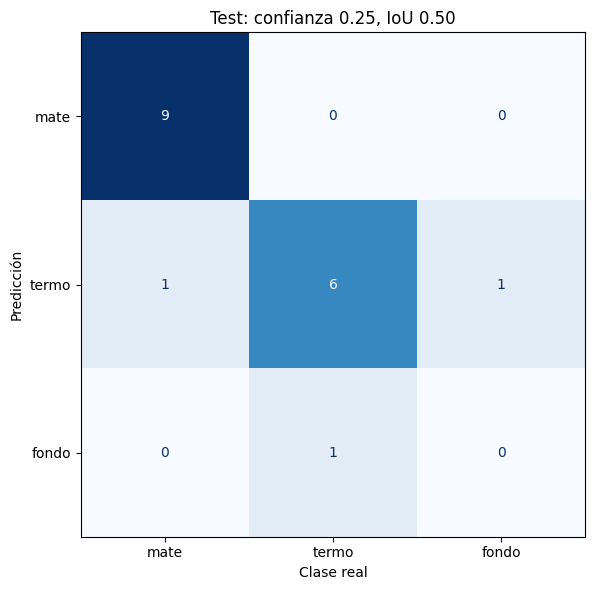

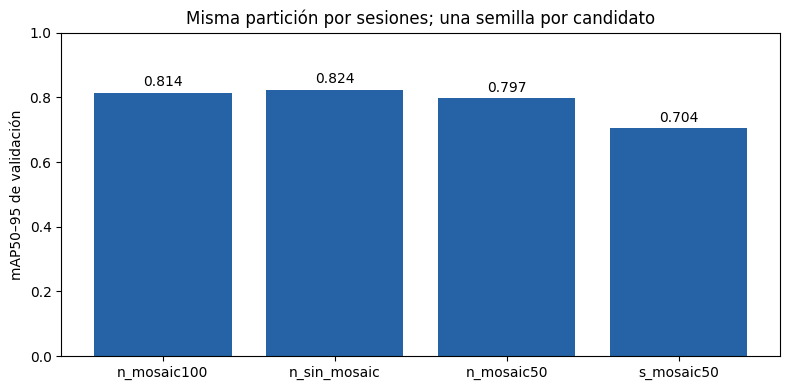

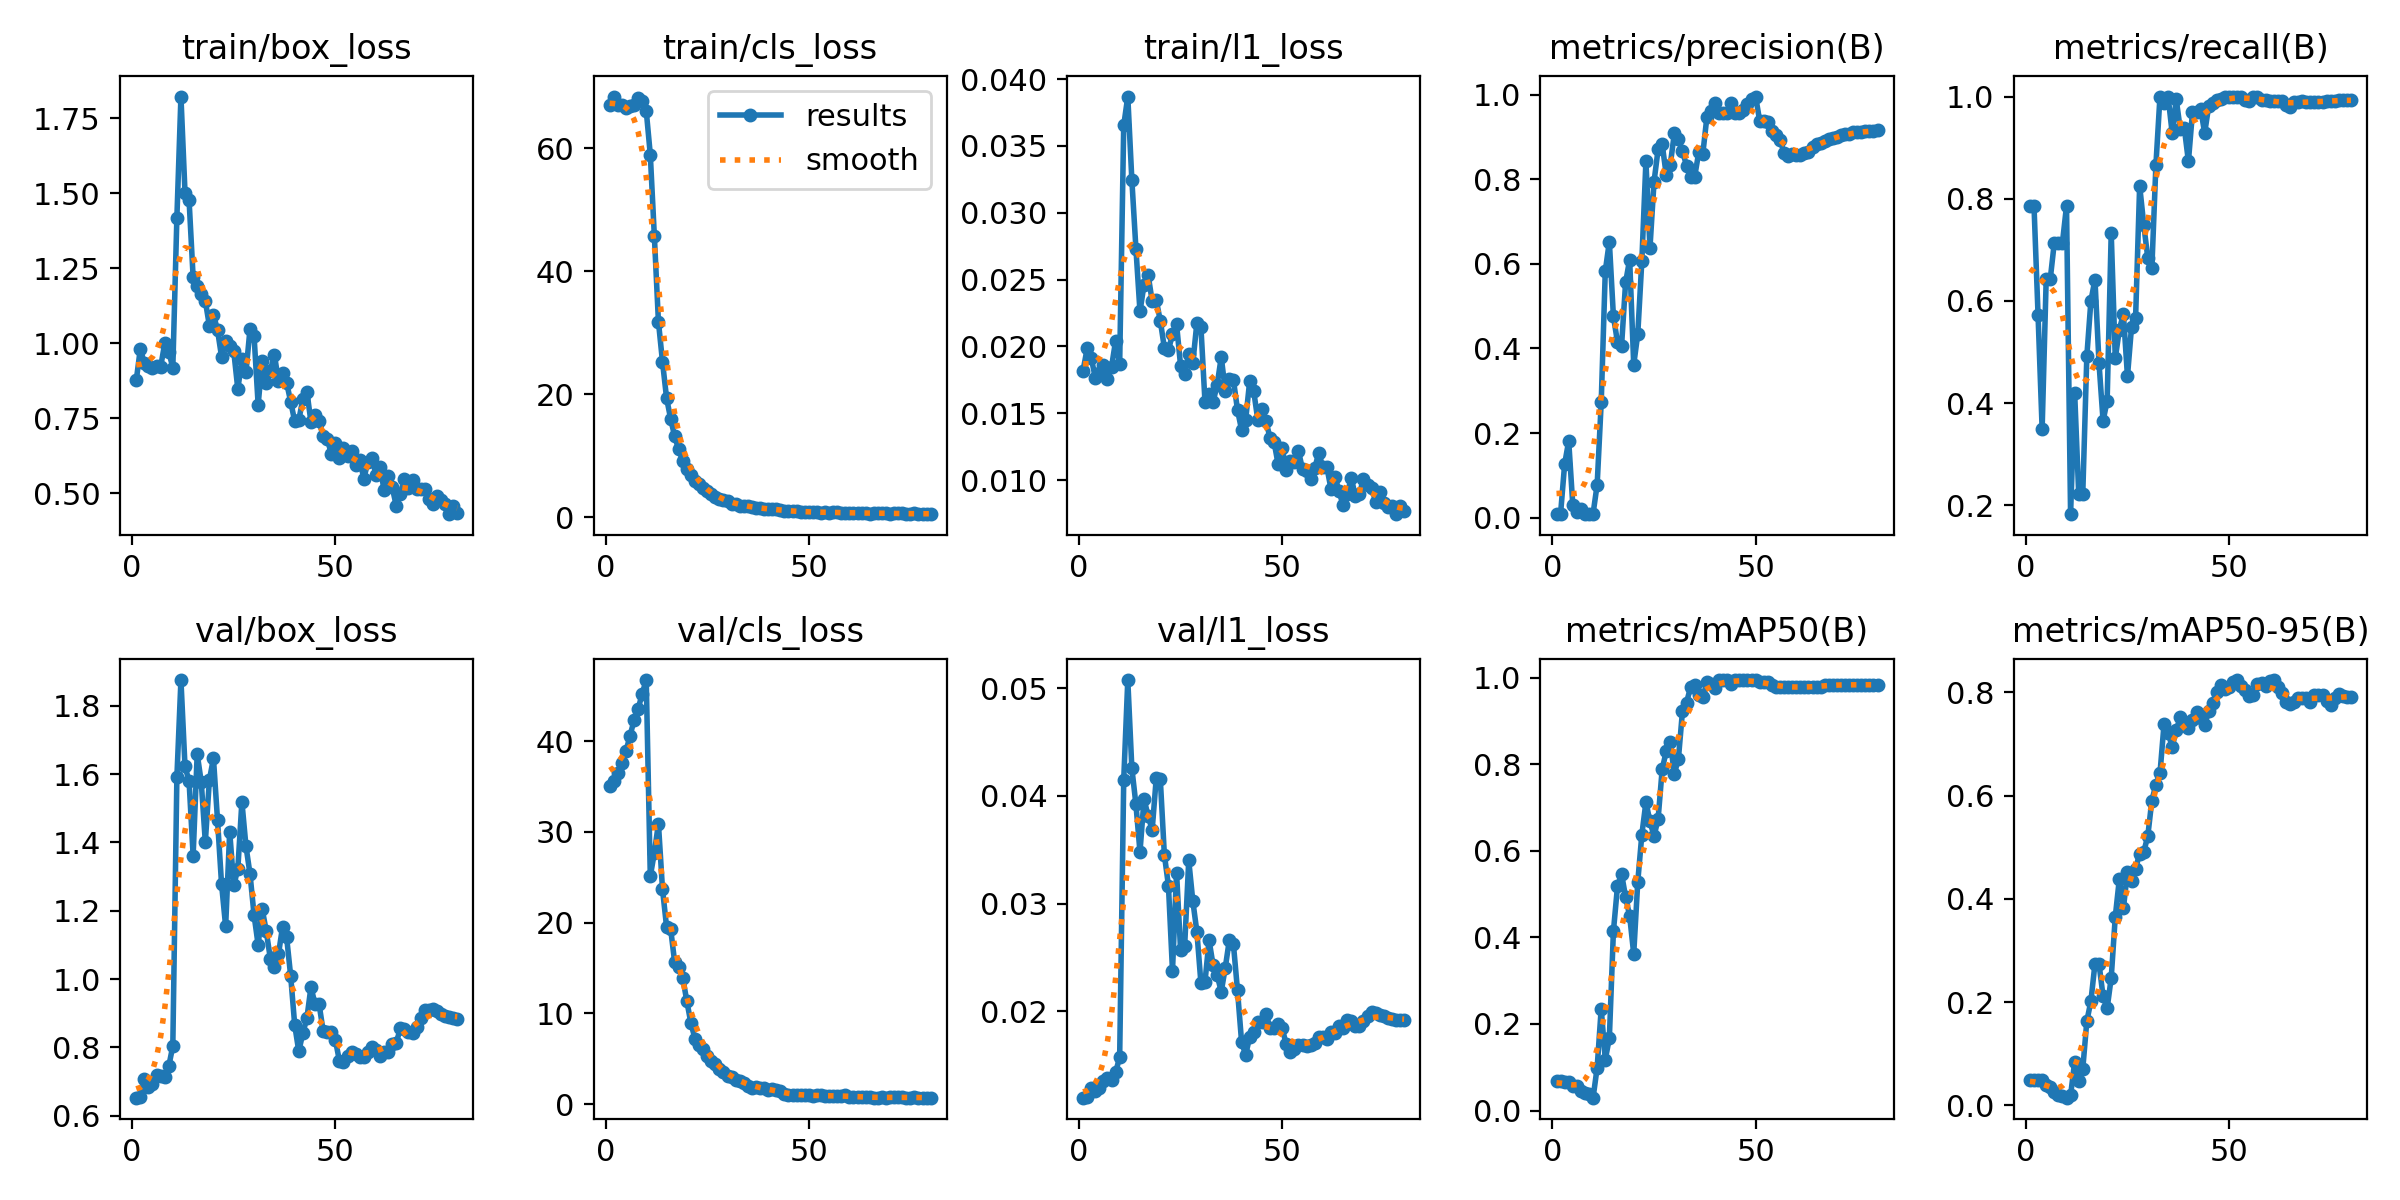

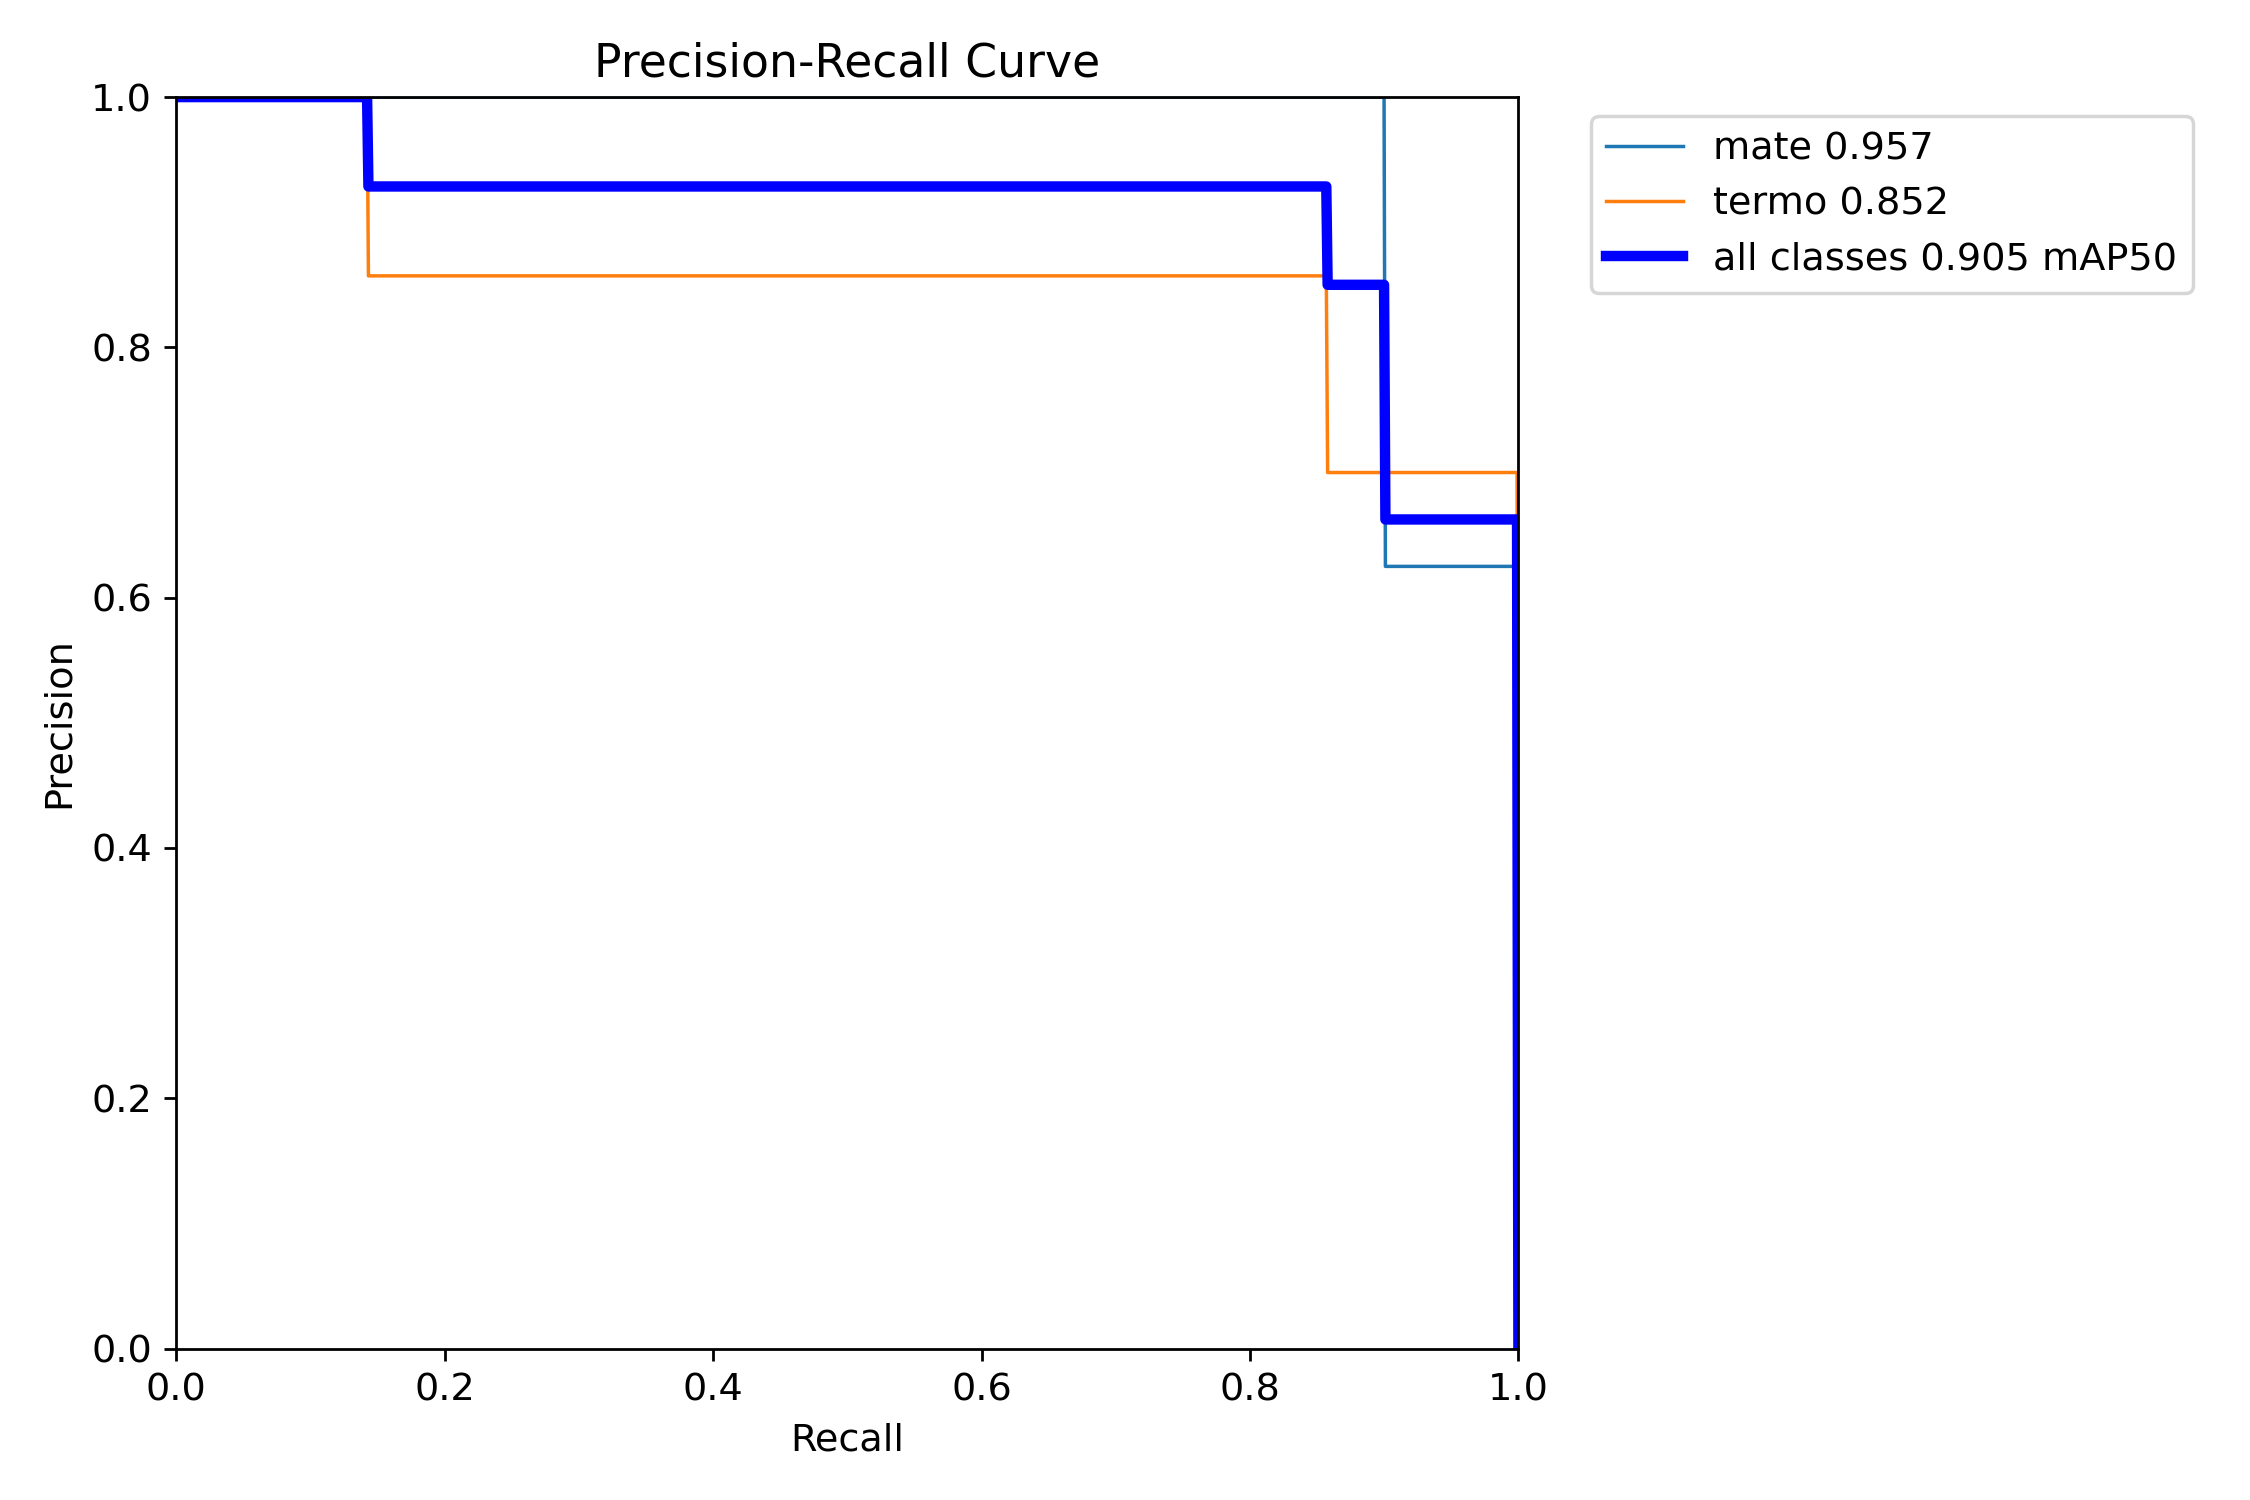

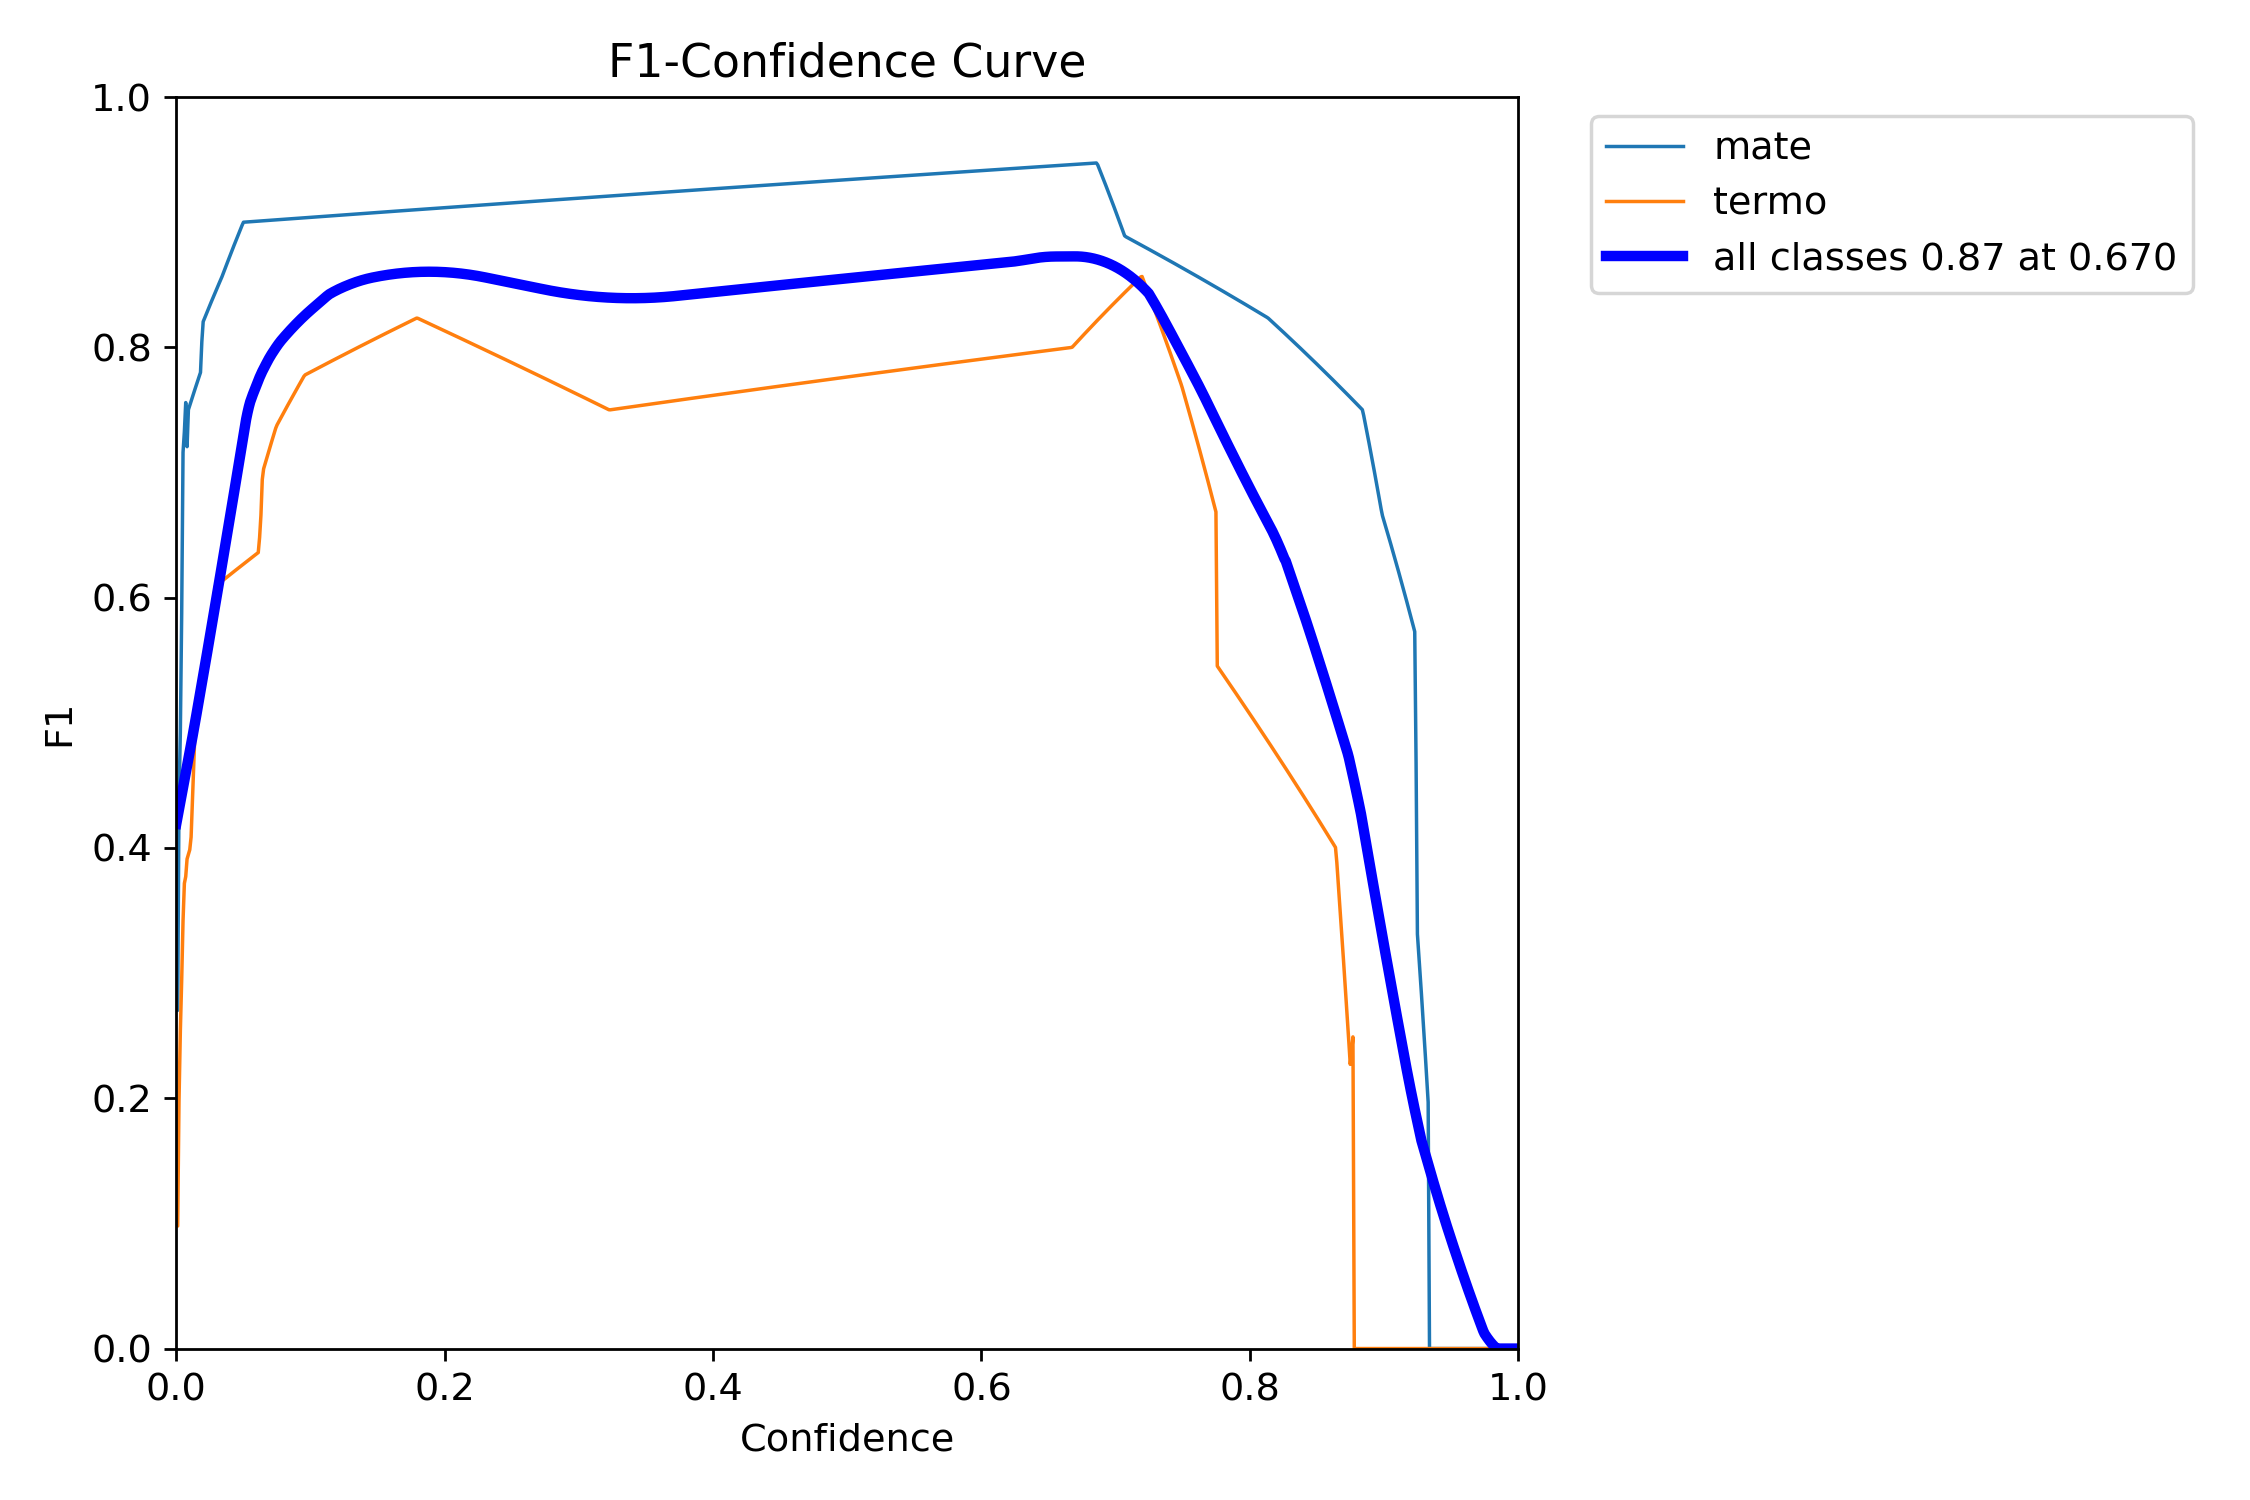

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

matrix = np.array(operative['matrix'])
labels = ['mate', 'termo', 'fondo']
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(matrix, display_labels=labels).plot(
    ax=ax, colorbar=False, cmap='Blues')
ax.set_xlabel('Clase real')
ax.set_ylabel('Predicción')
ax.set_title(f'Test: confianza {CONF_MATRIZ:.2f}, IoU 0.50')
fig.tight_layout()
fig.savefig(SUITE / 'confusion_matrix.png', dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
chart_data = pd.DataFrame(comparison)
ax.bar(chart_data['name'], chart_data['val_mAP50_95'], color='#2563a6')
ax.set_ylim(0, 1)
ax.set_ylabel('mAP50–95 de validación')
ax.set_title('Misma partición por sesiones; una semilla por candidato')
for idx, value in enumerate(chart_data['val_mAP50_95']):
    ax.text(idx, value + .02, f'{value:.3f}', ha='center')
fig.tight_layout()
fig.savefig(SUITE / 'comparacion_validacion.png', dpi=150)
plt.show()

GRAFICOS = [
    (BEST.parent.parent, 'results.png'),
    (SUITE / 'test_final', 'BoxPR_curve.png'),
    (SUITE / 'test_final', 'BoxF1_curve.png'),
]
for carpeta, nombre in GRAFICOS:
    path = carpeta / nombre
    if path.exists():
        display(IPyImage(filename=str(path), width=800))


## 9. Exportación

Se copian los pesos elegidos a `models/best.pt` y su confianza a `models/inferencia.json`, junto con el hash SHA-256 de los pesos. El notebook 02 lee ese archivo y verifica el hash.

Las métricas, la configuración, el barrido de confianza y las predicciones van a `resultados/comparacion_mejoras/`. Todo eso, más el dataset dividido, se empaqueta en `entregable_entrenamiento.zip`.

In [12]:
MODELS = ROOT / 'models'
RESULTADOS = ROOT / 'resultados/comparacion_mejoras'
MODELS.mkdir(exist_ok=True)
RESULTADOS.mkdir(parents=True, exist_ok=True)
shutil.copy2(BEST, MODELS / 'best.pt')
(MODELS / 'inferencia.json').write_text(json.dumps({
    'confidence': CONF_MATRIZ, 'imgsz': IMGSZ,
    'experiment': winner['name'], 'selection_split': 'val',
    'weights_sha256': hashlib.sha256(BEST.read_bytes()).hexdigest(),
}, indent=2), encoding='utf-8')
for path in SUITE.iterdir():
    if path.is_file():
        shutil.copy2(path, RESULTADOS / path.name)
for carpeta, nombre in GRAFICOS:
    if (carpeta / nombre).exists():
        shutil.copy2(carpeta / nombre, RESULTADOS / nombre)
shutil.copy2(BEST.parent.parent / 'results.csv', RESULTADOS / 'results.csv')
shutil.copy2(
    ROOT / 'data/split_manifest.csv', RESULTADOS / 'split_manifest.csv',
)
shutil.copy2(MODELS / 'inferencia.json', RESULTADOS / 'inferencia.json')

summary = (
    f"Seleccionado: {winner['name']} ({MODEL_BASE}), "
    f"mAP50-95 de validación={winner['val_mAP50_95']:.3f}. "
    f"Test: {report['test_images']} imágenes, "
    f"{report['test_instances']} objetos, "
    f"mAP50={report['mAP50']:.3f}, "
    f"mAP50-95={report['mAP50-95']:.3f}, "
    f"F1 macro={report['f1']:.3f} con confianza {CONF_MATRIZ:.2f}. "
    "La selección de modelo y confianza utilizó solo validación. "
    "Una única partición pequeña limita la generalización de estos valores."
)
print(summary)
(RESULTADOS / 'conclusiones.txt').write_text(summary, encoding='utf-8')

ENTREGABLE_ZIP = ROOT / 'entregable_entrenamiento.zip'
with zipfile.ZipFile(ENTREGABLE_ZIP, 'w', zipfile.ZIP_DEFLATED,
                     compresslevel=6) as zf:
    for file in DATASET.rglob('*'):
        if file.is_file() and file.suffix != '.cache':
            zf.write(file, f'dataset/{file.relative_to(DATASET)}')
    zf.write(BEST, 'models/best.pt')
    zf.write(MODELS / 'inferencia.json', 'models/inferencia.json')
    for file in RESULTADOS.iterdir():
        if file.is_file():
            zf.write(file, f'resultados/{file.name}')
print('Pesos:', MODELS / 'best.pt')
print('Resultados:', RESULTADOS)
print('ZIP:', ENTREGABLE_ZIP)


Seleccionado: n_sin_mosaic (yolo26n.pt), mAP50-95 de validación=0.824. Test: 14 imágenes, 17 objetos, mAP50=0.905, mAP50-95=0.593, F1 macro=0.874 con confianza 0.25. La selección de modelo y confianza utilizó solo validación. Una única partición pequeña limita la generalización de estos valores.
Pesos: /content/CV-mate-detection/models/best.pt
Resultados: /content/CV-mate-detection/resultados/comparacion_mejoras
ZIP: /content/CV-mate-detection/entregable_entrenamiento.zip


## 10. Conclusiones

**Datos.** El dataset tiene 90 fotos: 62 con mate (65 cajas) y 50 con termo (51 cajas); 22 fotos tienen los dos objetos. Al revisarlo corregimos un mate etiquetado como termo y agregamos cuatro cajas que faltaban. El split por sesiones quedó en 63 imágenes de entrenamiento, 13 de validación y 14 de test.

**Arquitectura y entrenamiento.** YOLO26n (260 capas, 2.504.580 parámetros, 5.9 GFLOPs) con transfer learning desde `yolo26n.pt` (COCO). Ultralytics reemplazó la cabeza para 2 clases y transfirió 696 de los 708 tensores. Se entrenó con batch 16, imágenes de 640 px, hasta 80 épocas con patience 20, AdamW (lr0 0.001667, elegido por `optimizer='auto'`) y semilla 42, en una Tesla T4 de Colab.

**Selección del modelo.** mAP50-95 en validación de cada candidato:

| Candidato | mAP50-95 (val) |
|---|---:|
| `n_sin_mosaic` | 0.824 |
| `n_mosaic100` | 0.814 |
| `n_mosaic50` | 0.797 |
| `s_mosaic50` | 0.704 |

Ganó YOLO26n sin mosaic. Completó las 80 épocas y su mejor valor fue en la 61; `best.pt` guarda los pesos de esa época. Desde la época 52 la pérdida de cajas en validación sube un poco mientras la de train sigue bajando, señal de un sobreajuste leve. Le saca 0.009 a la configuración por defecto (`n_mosaic100`), una diferencia que con una sola semilla no alcanza para afirmar que quitar mosaic ayuda. El modelo `s`, más grande, quedó último; con 63 imágenes de entrenamiento, más parámetros no se tradujeron en mejores resultados.

**Resultados en test.** Con confianza 0.25, elegida por F1 macro en validación, sobre 14 imágenes y 17 objetos:

| Métrica | Valor |
|---|---:|
| Precisión (macro) | 0.875 |
| Recall (macro) | 0.879 |
| F1 (macro) | 0.874 |
| mAP50 | 0.905 |
| mAP50-95 | 0.593 |

Por clase, el F1 de mate es 0.947 y el de termo 0.800. En la matriz hay 9 mates y 6 termos bien detectados, 1 mate clasificado como termo, 1 termo no detectado y 1 falso positivo de termo. El mAP50-95 queda bastante por debajo del mAP50: el modelo encuentra los objetos, pero las cajas no siempre ajustan bien al borde.

**Comparación con la primera corrida.** La primera corrida dio mAP50 0.708 en un test de 9 imágenes y 11 objetos. Los números no se pueden comparar: cambiaron las etiquetas y el split, y el modelo anterior había visto en entrenamiento parte de las fotos que ahora son test.

**Limitaciones.** Con 17 objetos en test, un solo error mueve el recall de mate 10 puntos y el de termo 14. En los videos del notebook 02 aparecen errores que el test no muestra: termos detectados sobre la cabeza o el torso de una persona y mates que se pierden por momentos. Lo que más ayudaría es sumar escenas nuevas, fotos de personas usando el mate y el termo, y negativos como tazas, pavas, botellas y caras. También convendría repetir la comparación con varias semillas o con validación cruzada por sesiones.

Pesos y confianza: `models/`. Métricas, predicciones y barrido de umbrales: `resultados/comparacion_mejoras/`. Informe completo: `docs/informe.md`.

In [13]:
print(summary)
print('Descargar resultados desde el explorador remoto:', ENTREGABLE_ZIP)

# Solo para Colab web. En VS Code: Colab > Contents > clic derecho > Download.
DESCARGAR_DESDE_COLAB_WEB = False
if IN_COLAB and DESCARGAR_DESDE_COLAB_WEB:
    from google.colab import files

    files.download(str(ENTREGABLE_ZIP))


Seleccionado: n_sin_mosaic (yolo26n.pt), mAP50-95 de validación=0.824. Test: 14 imágenes, 17 objetos, mAP50=0.905, mAP50-95=0.593, F1 macro=0.874 con confianza 0.25. La selección de modelo y confianza utilizó solo validación. Una única partición pequeña limita la generalización de estos valores.
Descargar resultados desde el explorador remoto: /content/CV-mate-detection/entregable_entrenamiento.zip
